# 04 - DATA VISUALISATION REVIEW EXERCISE - FLIGHTS (WITH SEABORN) (SOLUTIONS)

 Use the following datasets: "flights.csv" dataset contains information about the flights of an airport. "airlines.csv" dataset provides valuable information about flight routes, schedules, passenger demographics, and preferences, which airlines can leverage to optimize their operations and enhance customer experiences.


* Import the relevant libraries and read the dataset files

* Construct the same merged DataFrame as in the previous exercises (without missing values)

**Only use Seaborn to plot everything in these exercises!**

In [1]:
import sys; sys.path.append('..')  # so data_utils.py in the repo root can be found
from data_utils import get_data  # downloads big files from GitHub Releases if missing

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

# Read in data
flightsdf = pd.read_csv(get_data('data/flights.csv'))
airlinedf = pd.read_csv('data/airlines.csv')

In [2]:
flightsdf.dropna(inplace=True)
airlinedf.dropna(inplace=True)

In [3]:
flightsdf = flightsdf.merge(airlinedf, how='left', left_on='carrier', right_on='Passenger ID')
flights = flightsdf[['arr_delay', 'name']] 

Plot a histogram of Arrival Delays (figure size: (9,7), bins: 50, color: blue, provide title and x/y labels)

What does the kde argument do?

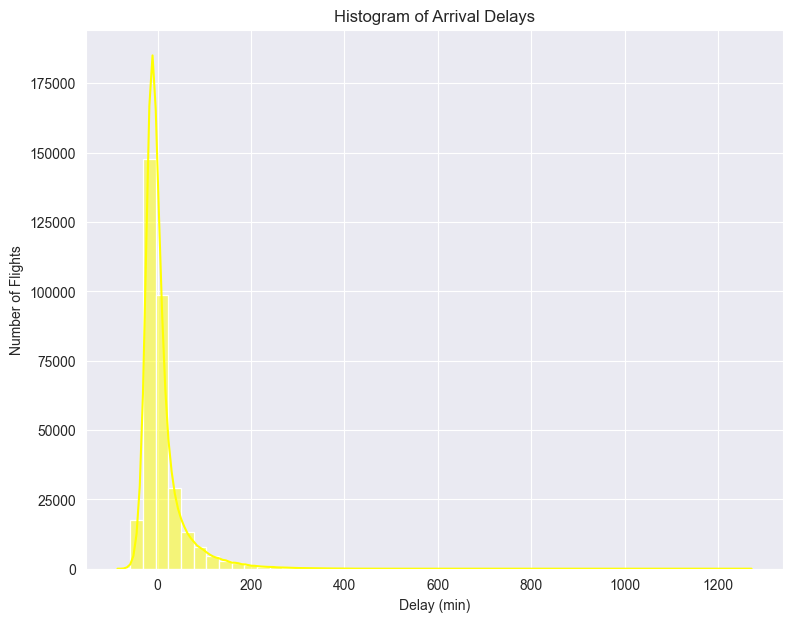

In [4]:
# Set the figure size
plt.figure(figsize=(9, 7))
# Plot using histplot
sns.histplot(flights['arr_delay'], kde=True, bins=50, color='yellow')
# kde=True will also show a smoothed estimation of the distribution
# Add titles and labels
plt.title('Histogram of Arrival Delays')
plt.xlabel('Delay (min)')
plt.ylabel('Number of Flights')
# Show plot
plt.show()

Plot four kernel density estimation plots in the same figure. Each should have a different bandwidth adjust argument. Use these values: [0.2, 0.5, 1, 5]. Provide a label showing which bw_adjust has been used.
(figure size: (12,7), provide legend with title, title, and x/y labels)

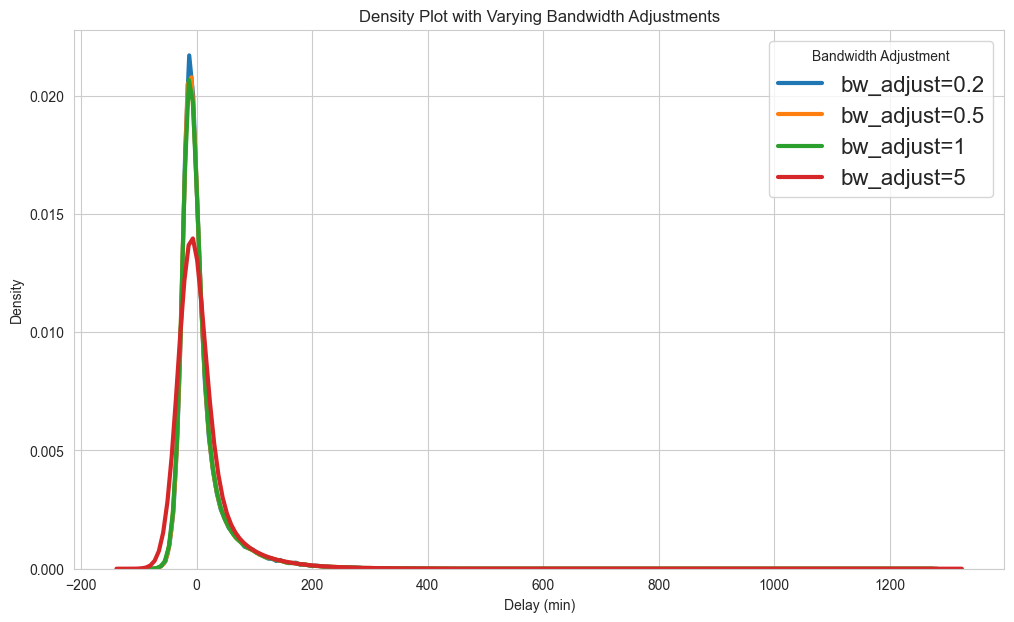

In [5]:
# Set the figure size
plt.figure(figsize=(12, 7))

# Loop through various bandwidth adjustments
for bandwidth_adjust in [0.2, 0.5, 1, 5]:
    sns.kdeplot(flights['arr_delay'], 
                bw_adjust=bandwidth_adjust, 
                linewidth=3, label=f'bw_adjust={bandwidth_adjust}')
# 0.2: very sharp peaks, possibly overfitting
# 1: default smoothing
# 5: very smooth, may hide details

# Add legend and labels
plt.legend(prop={'size': 16}, title='Bandwidth Adjustment')
plt.title('Density Plot with Varying Bandwidth Adjustments')
plt.xlabel('Delay (min)')
plt.ylabel('Density')

# Show plot
plt.show()


📊 What Does bw_adjust Do?
- KDE plots estimate the probability density function of a variable.
- Bandwidth determines how wide the kernel is — i.e., how much smoothing is applied.
- bw_adjust is a scaling factor:
* bw_adjust < 1 → narrower bandwidth, more sensitive to data → sharper, bumpier curve
* bw_adjust > 1 → wider bandwidth, more smoothing → flatter, smoother curv


Now also create 4 subplots (2x2) using plt.subplots() and plot each kde plots in one of them. Add legend and labels for each, also add one general title for all four plots.

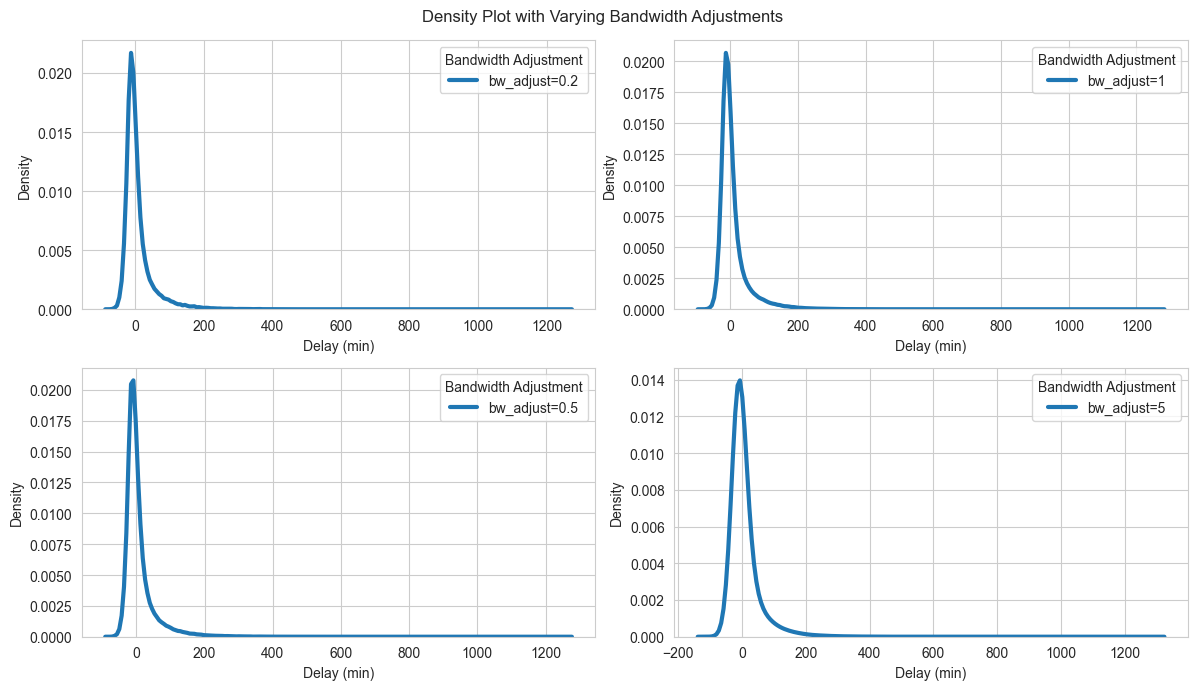

In [6]:
# Set the figure size
fig, axs = plt.subplots(2, 2, figsize=(12, 7))

# Loop through various bandwidth adjustments
for i, bandwidth_adjust in enumerate([0.2, 0.5, 1, 5]):
    sns.kdeplot(flights['arr_delay'],
                bw_adjust=bandwidth_adjust,
                linewidth=3, label=f'bw_adjust={bandwidth_adjust}', ax=axs[i%2, i//2])

    # Add legend and labels
    axs[i%2, i//2].legend(prop={'size': 10}, title='Bandwidth Adjustment')
    axs[i%2, i//2].set_xlabel('Delay (min)')
    axs[i%2, i//2].set_ylabel('Density')

fig.suptitle('Density Plot with Varying Bandwidth Adjustments')
plt.tight_layout() # Adjusts padding for subplots
# Show plot
plt.show()